# 05 — Modele GARCH pentru volatilitate

Pe reziduurile modelelor ARMA din etapa anterioară (estimate pe setul de antrenament) se compară:

- **specificații de volatilitate:** GARCH(1,1), EGARCH(1,1), GJR-GARCH(1,1), APARCH(1,1);
- **distribuții ale inovațiilor:** Normală și Student-t.

Selecția: cel mai mic AIC (apoi BIC) dintre modelele cu toți coeficienții semnificativi (p < 0.05, fără `omega` și parametrii de distribuție); dacă niciunul nu îndeplinește condiția, se alege cel mai mic AIC dintre toate. Diagnostic: Ljung-Box și ARCH-LM pe reziduurile standardizate.

In [1]:
import sys
import warnings
from pathlib import Path

# Face pachetul `src` importabil indiferent din ce folder se pornește notebookul
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from arch import arch_model
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.arima.model import ARIMA

from src import config, data
from src.garchx import split_train

df = data.load_master_dataset()

## 1. Reziduurile ARMA (set de antrenament)

In [2]:
reziduuri = {}
for var in config.ASSETS:
    train, _ = split_train(df[[var]].dropna())
    reziduuri[var] = ARIMA(train[var], order=config.ARMA_ORDERS[var]).fit().resid

c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
c:\User

## 2. Grila de modele (specificație × distribuție)

In [3]:
GRILA = [
    # (etichetă, vol, p, o, q)
    ("GARCH(1,1)", "GARCH", 1, 0, 1),
    ("EGARCH(1,1)", "EGARCH", 1, 1, 1),
    ("GJR-GARCH(1,1)", "GARCH", 1, 1, 1),
    ("APARCH(1,1)", "APARCH", 1, 1, 1),
]
DISTRIBUTII = {"N": "normal", "t": "t"}
PARAM_EXCLUSI = ["omega", "nu", "eta", "lambda"]

## 3. Estimare și selecție

In [4]:
toate, modele_optime, fit_optim = [], {}, {}

for var in config.ASSETS:
    candidati = []
    for eticheta, vol, p, o, q in GRILA:
        for sufix, dist in DISTRIBUTII.items():
            nume = f"{eticheta}-{sufix}"
            try:
                fit = arch_model(reziduuri[var] * 100, mean="Zero", vol=vol, p=p, o=o, q=q, dist=dist).fit(
                    disp="off", show_warning=False)
            except Exception as e:
                print(f"{var} {nume} — eroare: {e}")
                continue
            pvals = fit.pvalues.drop([c for c in PARAM_EXCLUSI if c in fit.pvalues.index], errors="ignore")
            candidati.append({"Serie": var, "Model": nume, "AIC": round(fit.aic, 4), "BIC": round(fit.bic, 4),
                              "Toti coef. semnificativi?": "DA" if (pvals < 0.05).all() else "NU", "_fit": fit})

    df_c = pd.DataFrame(candidati)
    valide = df_c[df_c["Toti coef. semnificativi?"] == "DA"]
    castigator = (valide if len(valide) else df_c).sort_values(["AIC", "BIC"]).iloc[0]
    modele_optime[var], fit_optim[var] = castigator["Model"], castigator["_fit"]
    toate += df_c.drop(columns="_fit").to_dict("records")

rezumat = pd.DataFrame([{"Activ": v, "Model Optim": modele_optime[v], "AIC": round(fit_optim[v].aic, 4),
                         "BIC": round(fit_optim[v].bic, 4)} for v in config.ASSETS])
rezumat

,Activ,Model Optim,AIC,BIC
0,Rand_SNP,"APARCH(1,1)-t",10111.4322,10147.6186
1,Rand_SNN,"GARCH(1,1)-t",8487.5211,8511.1310
2,Rand_H2O,"GARCH(1,1)-t",1555.2230,1573.2402
3,Rand_BET-NG,"APARCH(1,1)-t",7566.8263,7603.0127


## 4. Diagnostic pe reziduurile standardizate

In [5]:
ljung_box, arch_lm = [], []
for var in config.ASSETS:
    std_resid = fit_optim[var].std_resid.dropna()
    lb = acorr_ljungbox(std_resid, lags=[1, 5, 10, 20], return_df=True)
    for lag in [1, 5, 10, 20]:
        ljung_box.append({"Serie": var, "Model": modele_optime[var], "Lag": lag,
                          "Statistica testului": round(lb.loc[lag, "lb_stat"], 4),
                          "p-value": round(lb.loc[lag, "lb_pvalue"], 4),
                          "Exista autocorelare?": "NU" if lb.loc[lag, "lb_pvalue"] > 0.05 else "DA"})
    for lag in [1, 4, 8, 12]:
        stat, p, _, _ = het_arch(std_resid, nlags=lag)
        arch_lm.append({"Serie": var, "Model": modele_optime[var], "Lag ARCH": lag,
                        "Statistica LM": round(stat, 4), "p-value": "< 0.0001" if p < 0.0001 else f"{p:.4f}",
                        "Exista efecte ARCH reziduale?": "DA" if p < 0.05 else "NU"})
pd.DataFrame(ljung_box)

,Serie,Model,Lag,Statistica testului,p-value,Exista autocorelare?
0,Rand_SNP,"APARCH(1,1)-t",1,0.9903,0.3197,NU
1,Rand_SNP,"APARCH(1,1)-t",5,5.1352,0.3996,NU
2,Rand_SNP,"APARCH(1,1)-t",10,10.5030,0.3975,NU
3,Rand_SNP,"APARCH(1,1)-t",20,20.4386,0.4308,NU
4,Rand_SNN,"GARCH(1,1)-t",1,0.3034,0.5818,NU
5,Rand_SNN,"GARCH(1,1)-t",5,4.1181,0.5325,NU
6,Rand_SNN,"GARCH(1,1)-t",10,9.4389,0.4910,NU
7,Rand_SNN,"GARCH(1,1)-t",20,16.1588,0.7067,NU
8,Rand_H2O,"GARCH(1,1)-t",1,0.0685,0.7936,NU
9,Rand_H2O,"GARCH(1,1)-t",5,6.8286,0.2337,NU


In [6]:
pd.DataFrame(arch_lm)

,Serie,Model,Lag ARCH,Statistica LM,p-value,Exista efecte ARCH reziduale?
0,Rand_SNP,"APARCH(1,1)-t",1,0.6135,0.4335,NU
1,Rand_SNP,"APARCH(1,1)-t",4,2.5776,0.6308,NU
2,Rand_SNP,"APARCH(1,1)-t",8,4.4461,0.8148,NU
3,Rand_SNP,"APARCH(1,1)-t",12,7.0311,0.8555,NU
4,Rand_SNN,"GARCH(1,1)-t",1,0.3138,0.5753,NU
5,Rand_SNN,"GARCH(1,1)-t",4,0.9096,0.9232,NU
6,Rand_SNN,"GARCH(1,1)-t",8,1.6815,0.9893,NU
7,Rand_SNN,"GARCH(1,1)-t",12,1.8783,0.9996,NU
8,Rand_H2O,"GARCH(1,1)-t",1,0.0040,0.9498,NU
9,Rand_H2O,"GARCH(1,1)-t",4,2.9093,0.5731,NU


## 5. Volatilitatea condiționată estimată

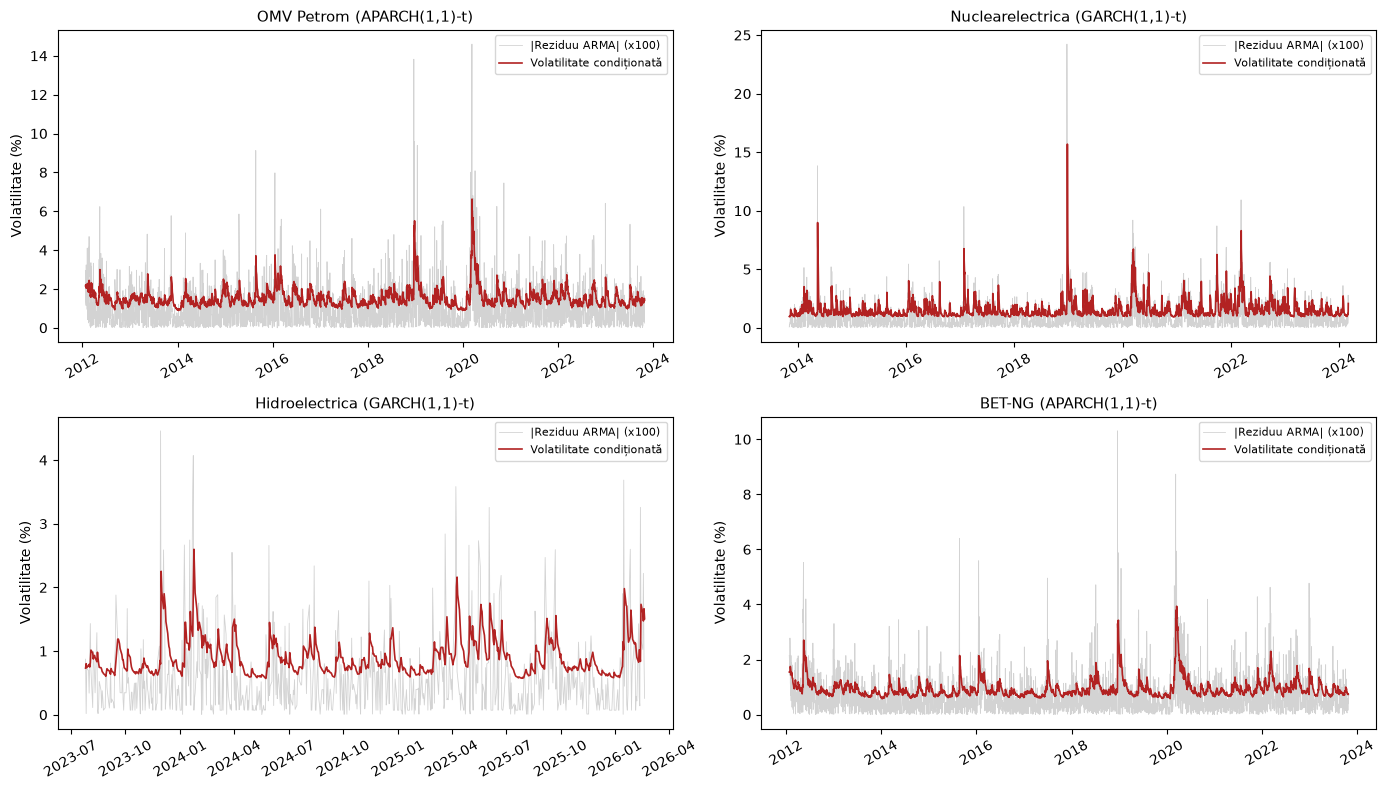

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, var in zip(axes.flatten(), config.ASSETS):
    vol = fit_optim[var].conditional_volatility
    rezid = reziduuri[var]
    ax.plot(rezid.index[:len(vol)], np.abs(rezid.values[:len(vol)]) * 100, color="lightgray", linewidth=0.6,
            label="|Reziduu ARMA| (x100)", zorder=1)
    ax.plot(rezid.index[:len(vol)], vol, color="firebrick", linewidth=1.2, label="Volatilitate condiționată", zorder=2)
    ax.set_title(f"{config.ASSET_NAMES[var]} ({modele_optime[var]})", fontsize=11)
    ax.set_ylabel("Volatilitate (%)")
    ax.legend(fontsize=8)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(config.FIG_DIR / "garch_conditional_volatility.png", dpi=300, bbox_inches="tight")

## 6. Export

In [8]:
enc = "utf-8-sig"
pd.DataFrame(toate).to_csv(config.TABLE_DIR / "garch_all_models.csv", index=False, encoding=enc)
rezumat.to_csv(config.TABLE_DIR / "garch_optimal_models.csv", index=False, encoding=enc)
pd.DataFrame(ljung_box).to_csv(config.TABLE_DIR / "garch_ljung_box.csv", index=False, encoding=enc)
pd.DataFrame(arch_lm).to_csv(config.TABLE_DIR / "garch_arch_lm.csv", index=False, encoding=enc)